# MaskFormer Training on Welding Robot Data

End-to-end training pipeline for `GLCAnomalyMaskFormer` using the mock welding robot dataset.

**Pipeline:**
1. Load and explore CSV (1.84M timesteps, 3 sensors, 250ms intervals)
2. Group consecutive timesteps into macro-windows (seq_len=240), with padding
3. Build `RawWindowDataset` with robot/program indices
4. Initialize MaskFormer (num_sensors=3)
5. Train with `MaskFormerTrainerRunner`
6. Visualize training curves

In [1]:
# %% Imports
import sys
import os
import json
import math
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import matplotlib.pyplot as plt

# Add project root to path
project_root = Path.cwd().parent.parent.resolve()
print(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from app.anomaly_detection.utils import set_random_seed
set_random_seed(42)
print("Random seed set to 42")

from app.anomaly_detection.models import (
    create_model,
    filter_model_kwargs,
    MaskFormerModels,
)
from app.anomaly_detection.training.maskformer_trainer import (
    MaskFormerTrainerRunner,
)
from app.anomaly_detection.training.datasets import RawWindowDataset

print("All imports OK")
print(f"PyTorch {torch.__version__}, CUDA available: {torch.cuda.is_available()}")


/home/trietlm/TED-Hackathon-Agent
Random seed set to 42
All imports OK
PyTorch 2.12.0+cu130, CUDA available: True


## 1. Load and Explore Data

In [2]:
# Load the full CSV
CSV_PATH = project_root / "data" / "mock_welding_robot_data.csv"
print(f"Reading {CSV_PATH}...")

import csv
with open(CSV_PATH, "r") as f:
    reader = csv.DictReader(f)
    rows = list(reader)

print(f"Total rows: {len(rows):,}")
print(f"Columns: {list(rows[0].keys())}")

# Sensor columns
SENSOR_COLS = ["wire_feed_speed_m_min", "wire_temperature_c", "welding_current_a"]
print(f"Sensor columns: {SENSOR_COLS}")

# Quick stats
robot_codes = sorted(set(r["robot_code"] for r in rows))
program_nums = sorted(set(r["program_number"] for r in rows))
phases = sorted(set(r["phase"] for r in rows))
print(f"Robot codes: {robot_codes}")
print(f"Program numbers: {program_nums}")
print(f"Phases: {phases}")
print(f"Example row: {dict(list(rows[0].items())[:6])}")


Reading /home/trietlm/TED-Hackathon-Agent/data/mock_welding_robot_data.csv...
Total rows: 1,842,401
Columns: ['robot_code', 'start_time', 'program_number', 'infer_recorded_date', 'serial_number', 'phase', 'wire_feed_speed_m_min', 'wire_temperature_c', 'welding_current_a', 'timestamp']
Sensor columns: ['wire_feed_speed_m_min', 'wire_temperature_c', 'welding_current_a']
Robot codes: ['6']
Program numbers: ['116']
Phases: ['active', 'idle', 'rampup', 'shutdown', 'winddown']
Example row: {'robot_code': '6', 'start_time': '2025-07-01 00:00:00', 'program_number': '116', 'infer_recorded_date': '2025-07-01 00:00:00.000', 'serial_number': '1', 'phase': 'idle'}


## 2. Merge into Macro-Windows with Padding

Each "file" = unique `(robot_code, start_time, program_number)` group.
Rows within a group are ordered by `serial_number`.
We extract the 3 sensor values, zero-pad to `seq_len=240` if shorter, or slice if longer.

In [4]:
SEQ_LEN = 240  # MaskFormer default macro-window length
STRIDE = 40  # Set stride here, you can change this
NUM_SENSORS = 3  # wire_feed_speed, welding_voltage, welding_current

# Group rows by (robot_code, start_time, program_number)
groups = defaultdict(list)
for r in rows:
    # Ensure start_time is a string
    key = (str(r["robot_code"]), str(r["start_time"]), str(r["program_number"]))
    groups[key].append(r)

print(f"Total groups (files): {len(groups)}")

# Build windows: each group â†’ one file-window [C, T]
windows_list = []
robot_idx_list = []
program_idx_list = []
group_keys = []

# Build robot and program codebooks
all_robot_codes = sorted(set(str(r["robot_code"]) for r in rows))
all_program_nums = sorted(set(str(r["program_number"]) for r in rows))
robot_to_idx = {code: i for i, code in enumerate(all_robot_codes)}
program_to_idx = {pn: i for i, pn in enumerate(all_program_nums)}

print(f"Robot codebook: {len(robot_to_idx)} codes â†’ indices 0..{len(robot_to_idx)-1}")
print(f"Program codebook: {len(program_to_idx)} programs â†’ indices 0..{len(program_to_idx)-1}")

for key, group_rows in groups.items():
    # Sort by serial_number (ascending)
    group_rows.sort(key=lambda x: int(x["serial_number"]))
    
    # Extract sensor values as float array [T, C]
    file_arr = np.array(
        [[float(r[col]) for col in SENSOR_COLS] for r in group_rows],
        dtype=np.float32,
    )  # [T, C]
    
    T = file_arr.shape[0]
    
    if T >= SEQ_LEN:
        # Extract multiple windows with the given stride
        for start_idx in range(0, T - SEQ_LEN + 1, STRIDE):
            window = file_arr[start_idx : start_idx + SEQ_LEN, :].T  # [C, T]
            windows_list.append(window)
            robot_idx_list.append(robot_to_idx[key[0]])
            program_idx_list.append(program_to_idx[key[2]])
            group_keys.append(key)
        
        # Optionally, handle the remaining tail by padding if needed
        # (Often ignored if the tail is too short and already covered by a previous overlapped window)
        tail_start = (T - SEQ_LEN) // STRIDE * STRIDE + STRIDE
        if tail_start < T and T - tail_start > 0:
            tail = file_arr[tail_start:, :]
            pad = np.zeros((SEQ_LEN - tail.shape[0], NUM_SENSORS), dtype=np.float32)
            window = np.vstack([tail, pad]).T
            windows_list.append(window)
            robot_idx_list.append(robot_to_idx[key[0]])
            program_idx_list.append(program_to_idx[key[2]])
            group_keys.append(key)
    else:
        # Zero-pad to SEQ_LEN
        pad = np.zeros((SEQ_LEN - T, NUM_SENSORS), dtype=np.float32)
        window = np.vstack([file_arr, pad]).T  # [C, T]
        windows_list.append(window)
        robot_idx_list.append(robot_to_idx[key[0]])
        program_idx_list.append(program_to_idx[key[2]])
        group_keys.append(key)

# Stack into arrays
windows_arr = np.stack(windows_list, axis=0)  # [N, C, T]
robot_arr = np.array(robot_idx_list, dtype=np.int64)
program_arr = np.array(program_idx_list, dtype=np.int64)

print(f"\nWindows shape: {windows_arr.shape}  [N, C={NUM_SENSORS}, T={SEQ_LEN}]")
print(f"Robot indices shape: {robot_arr.shape}, unique: {np.unique(robot_arr)}")
print(f"Program indices shape: {program_arr.shape}, unique: {np.unique(program_arr)}")
print(f"Sensor value range: [{windows_arr.min():.4f}, {windows_arr.max():.4f}]")

Total groups (files): 6000
Robot codebook: 1 codes â†’ indices 0..0
Program codebook: 1 programs â†’ indices 0..0

Windows shape: (19260, 3, 240)  [N, C=3, T=240]
Robot indices shape: (19260,), unique: [0]
Program indices shape: (19260,), unique: [0]
Sensor value range: [0.0000, 355.0000]


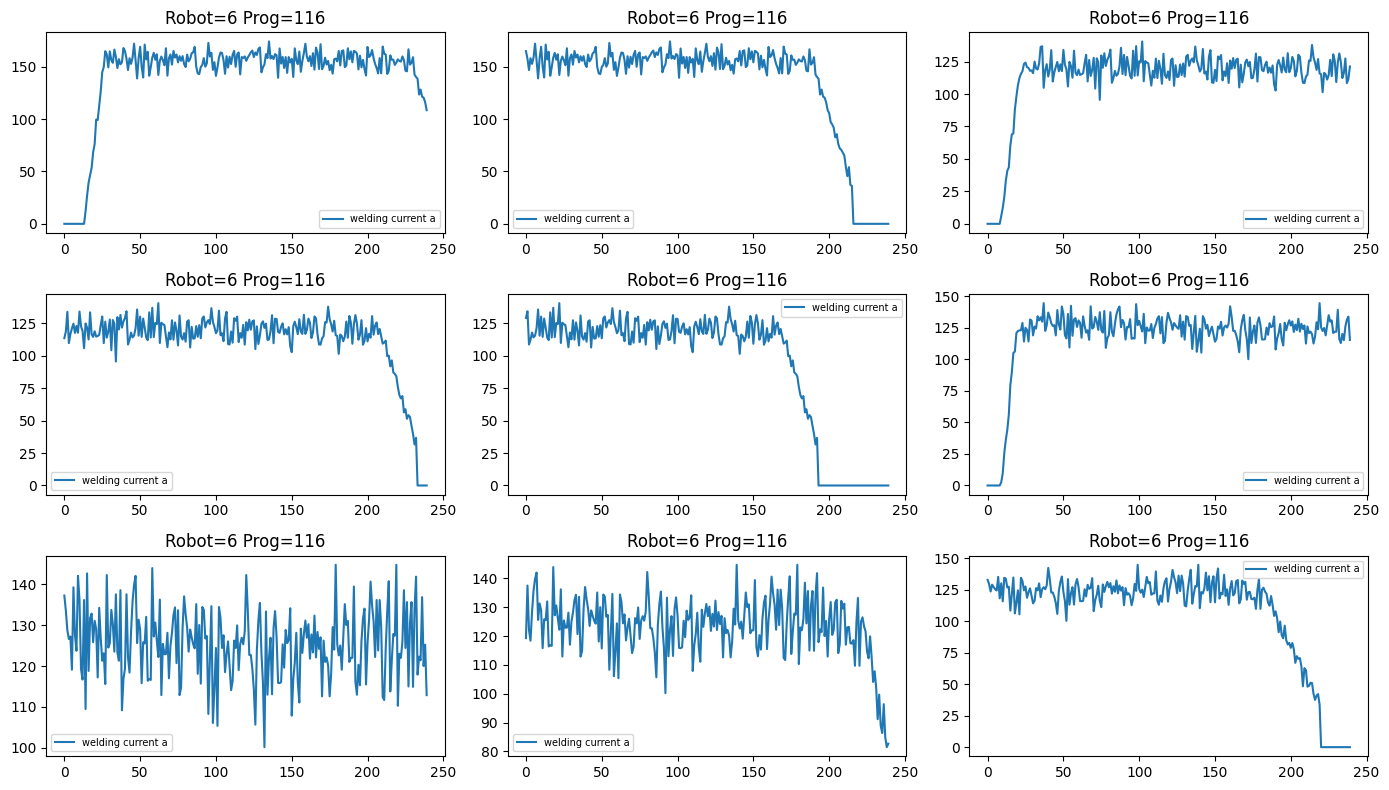

In [5]:
# Quick sanity: plot a few file-windows
fig, axes = plt.subplots(3, 3, figsize=(14, 8))
for i in range(3):
    for j in range(3):
        idx = i * 3 + j
        ax = axes[i, j]
        w = windows_arr[idx]
        for s in range(NUM_SENSORS):
            if s != 2:
                continue
            ax.plot(w[s], label=SENSOR_COLS[s].replace("_", " "))
        ax.set_title(f"Robot={group_keys[idx][0]} Prog={group_keys[idx][2]}")
        ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


### Window Generation Test

Let's test if the mathematically expected number of windows matches what was extracted, and print out the starting serial number for each stride offset.

In [6]:
# Test cell to verify the number of windows and starting serials for a sampled file

# Let's take the first file from our groups dictionary
sample_key = list(groups.keys())[2]
sample_group = groups[sample_key]
T = len(sample_group)

print(f"Testing for file (Robot={sample_key[0]}, Program={sample_key[2]})")
print(f"Total timesteps (rows) in file: T = {T}")
print(f"SEQ_LEN = {SEQ_LEN}, STRIDE = {STRIDE}")

# Mathematical calculation for expected number of windows
if T >= SEQ_LEN:
    expected_full_windows = (T - SEQ_LEN) // STRIDE + 1
    tail_start = expected_full_windows * STRIDE
    expected_tail = 1 if tail_start < T and (T - tail_start > 0) else 0
    expected_total_windows = expected_full_windows + expected_tail
else:
    expected_full_windows = 0
    expected_tail = 1
    expected_total_windows = 1

print(f"Expected Full Windows: {expected_full_windows}")
print(f"Expected Tail Windows: {expected_tail}")
print(f"Expected Total Windows: {expected_total_windows}")

# Let's count how many windows actually exist for this key in the lists we generated
actual_windows_idx = [i for i, k in enumerate(group_keys) if k == sample_key]
actual_total_windows = len(actual_windows_idx)

print(f"Actual Total Windows Gen'd: {actual_total_windows}")
assert actual_total_windows == expected_total_windows, "Mismatch in window counts!"

print("\nChecking Starting Serials / Indices:")
if T >= SEQ_LEN:
    for w_idx in range(expected_full_windows):
        start_idx = w_idx * STRIDE
        start_serial = int(sample_group[start_idx]["serial_number"])
        print(f"  Window {w_idx}: starts at index {start_idx}, serial_number {start_serial}")
    
    if expected_tail:
        tail_start = expected_full_windows * STRIDE
        start_serial = int(sample_group[tail_start]["serial_number"])
        print(f"  Tail Window: starts at index {tail_start}, serial_number {start_serial}")
else:
    start_serial = int(sample_group[0]["serial_number"])
    print(f"  Single Padded Window: starts at index 0, padding up to {SEQ_LEN}, serial_number {start_serial}")

print("\nTest passed successfully! ðŸŽ‰")

Testing for file (Robot=6, Program=116)
Total timesteps (rows) in file: T = 353
SEQ_LEN = 240, STRIDE = 40
Expected Full Windows: 3
Expected Tail Windows: 1
Expected Total Windows: 4
Actual Total Windows Gen'd: 4

Checking Starting Serials / Indices:
  Window 0: starts at index 0, serial_number 1
  Window 1: starts at index 40, serial_number 41
  Window 2: starts at index 80, serial_number 81
  Tail Window: starts at index 120, serial_number 121

Test passed successfully! ðŸŽ‰


## 3. Create Dataset and DataLoader

In [7]:
# Split into train/val (80/20)
N = len(windows_arr)

indices = np.random.permutation(N)
split = int(0.8 * N)
train_idx = indices[:split]
val_idx = indices[split:]

train_dataset = RawWindowDataset(
    windows=windows_arr[train_idx],
    robot_indices=robot_arr[train_idx],
    program_indices=program_arr[train_idx],
)
val_dataset = RawWindowDataset(
    windows=windows_arr[val_idx],
    robot_indices=robot_arr[val_idx],
    program_indices=program_arr[val_idx],
)

print(f"Train files: {len(train_dataset)}")
print(f"Val files:   {len(val_dataset)}")
print(f"Sample output keys: {list(train_dataset[0].keys())}")
print(f"  input shape: {train_dataset[0]['input'].shape}")
print(f"  robot_idx:   {train_dataset[0]['robot_idx']}")
print(f"  program_idx: {train_dataset[0]['program_idx']}")


Train files: 15408
Val files:   3852
Sample output keys: ['input', 'robot_idx', 'program_idx']
  input shape: torch.Size([3, 240])
  robot_idx:   0
  program_idx: 0


## 4. Initialize MaskFormer Model

Key config adjustments for welding data:
- `num_sensors=3` (wire_feed_speed, welding_voltage, welding_current)
- `num_robots` set to actual unique robot count
- `num_programs` set to actual unique program count

In [ ]:
from app.anomaly_detection.models.glc_anomaly_maskformer import GLCAnomalyMaskFormerConfig
num_unique_robots = len(np.unique(robot_arr))
num_unique_programs = len(np.unique(program_arr))

config = GLCAnomalyMaskFormerConfig(
    num_sensors=NUM_SENSORS,
    seq_len=SEQ_LEN,
    num_robots=32,
    num_programs=256,
    patch_size=32,
    patch_stride=16,
    d_model=128,
    transformer_layers=4,
    transformer_heads=4,
    ffn_dim=512,
    dropout=0.1,
    mask_ratio=0.15,
    initial_sigma=4.5,
    use_context_embeddings=True,
    use_cnn_decoder=True,
)

model = create_model(MaskFormerModels.GLC_ANOMALY_MASKFORMER, config)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model: {model.name}")
print(f"Total params: {total_params:,}")
print(f"Trainable params: {trainable_params:,}")

Model: GLCAnomalyMaskFormer
Total params: 857,479
Trainable params: 857,479


## 5. Initialize Trainer and Train

In [9]:
BATCH_SIZE = 32
EPOCHS = 30
LR = 1e-4

# Create DataLoaders
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
)
val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
)

print(f"Batches per epoch: train={len(train_loader)}, val={len(val_loader)}")

# Build runner and train
# lambda_end=0.2: JS divergence is bounded in [0, log(2)≈0.693].
# With lambda_end=2.0, the Phase A loss -lambda*assoc dominated the adversarial
# gradient and drove A_series to uniform → JS saturated at ~0.62 (ceiling).
# lambda_end=0.2 keeps the assoc gradient comparable to recon gradient.
runner = MaskFormerTrainerRunner(model_or_config=model,
                                 lambda_assoc=0.002,
                                 lambda_orth=0.1,
                                 lr_sigma_scale=0.1,
                                 sigma_max=10.0,
                                 warmup_epochs=10,
                                 lambda_end=0.008,
                                 lambda_ramp_epochs=10,
                                 log_grad_norms=True)
history = runner.train(
    train_loader=list(train_loader),
    val_loader=list(val_loader),
    epochs=EPOCHS,
    lr=LR,
)

print("\n" + "=" * 60)
print("TRAINING COMPLETE — HEALTH SIGNALS")
print("=" * 60)
print(f"  recon_loss:       {history['recon_loss'][0]:.4f} → {history['recon_loss'][-1]:.4f}  (MUST trend down)")
print(f"  assoc_loss:       {history['assoc_loss_min'][0]:.4f} → {history['assoc_loss_min'][-1]:.4f}  (JS in [0, 0.693])")
print(f"  discrepancy_std:  {history['discrepancy_std'][0]:.4f} → {history['discrepancy_std'][-1]:.4f}  (higher = more spatial variation = better)")
if history.get("grad_ratio") and len(history["grad_ratio"]) > 0:
    print(f"  grad_ratio:       {history['grad_ratio'][0]:.2f} → {history['grad_ratio'][-1]:.2f}  (assoc/recon QKV grad — keep < 10x)")
print(f"  sigma_mean:       {history['sigma_mean'][0]:.3f} → {history['sigma_mean'][-1]:.3f}")
if history["assoc_loss_min"][-1] > 0.6:
    print("\n  WARNING: JS near saturation (>0.6). Lower lambda_end further.")
print("=" * 60)
print("Healthy: recon_loss down + discrepancy_std rising + assoc < 0.6")
print("=" * 60)


Batches per epoch: train=481, val=121


Epochs:   0%|          | 0/30 [00:00<?, ?epoch/s]

Epoch 1/30:   0%|          | 0/481 [00:00<?, ?batch/s]

Epoch 1/30 (Val):   0%|          | 0/121 [00:00<?, ?batch/s]

Epoch 1/30 — recon: 0.3416  assoc: 0.2962  dstd: 0.047  λ: 0.0020  sigma: 4.500  val: 0.1963  grad_r: 0.00  **best**


...

Epoch 29/30 (Val):   0%|          | 0/121 [00:00<?, ?batch/s]

Epoch 29/30 — recon: 0.2352  assoc: 0.5225  dstd: 0.148  λ: 0.0080  sigma: 4.595  val: -0.0043  grad_r: 0.01  **best**


Epoch 30/30:   0%|          | 0/481 [00:00<?, ?batch/s]

Epoch 30/30 (Val):   0%|          | 0/121 [00:00<?, ?batch/s]

Epoch 30/30 — recon: 0.2355  assoc: 0.5267  dstd: 0.147  λ: 0.0080  sigma: 4.599  val: -0.0043  grad_r: 0.01  **best**

TRAINING COMPLETE — HEALTH SIGNALS
  recon_loss:       0.3416 → 0.2355  (MUST trend down)
  assoc_loss:       0.2962 → 0.5267  (JS in [0, 0.693])
  discrepancy_std:  0.0475 → 0.1467  (higher = more spatial variation = better)
  grad_ratio:       0.00 → 0.01  (assoc/recon QKV grad — keep < 10x)
  sigma_mean:       4.500 → 4.599
Healthy: recon_loss down + discrepancy_std rising + assoc < 0.6


## 6. Visualize Training Curves

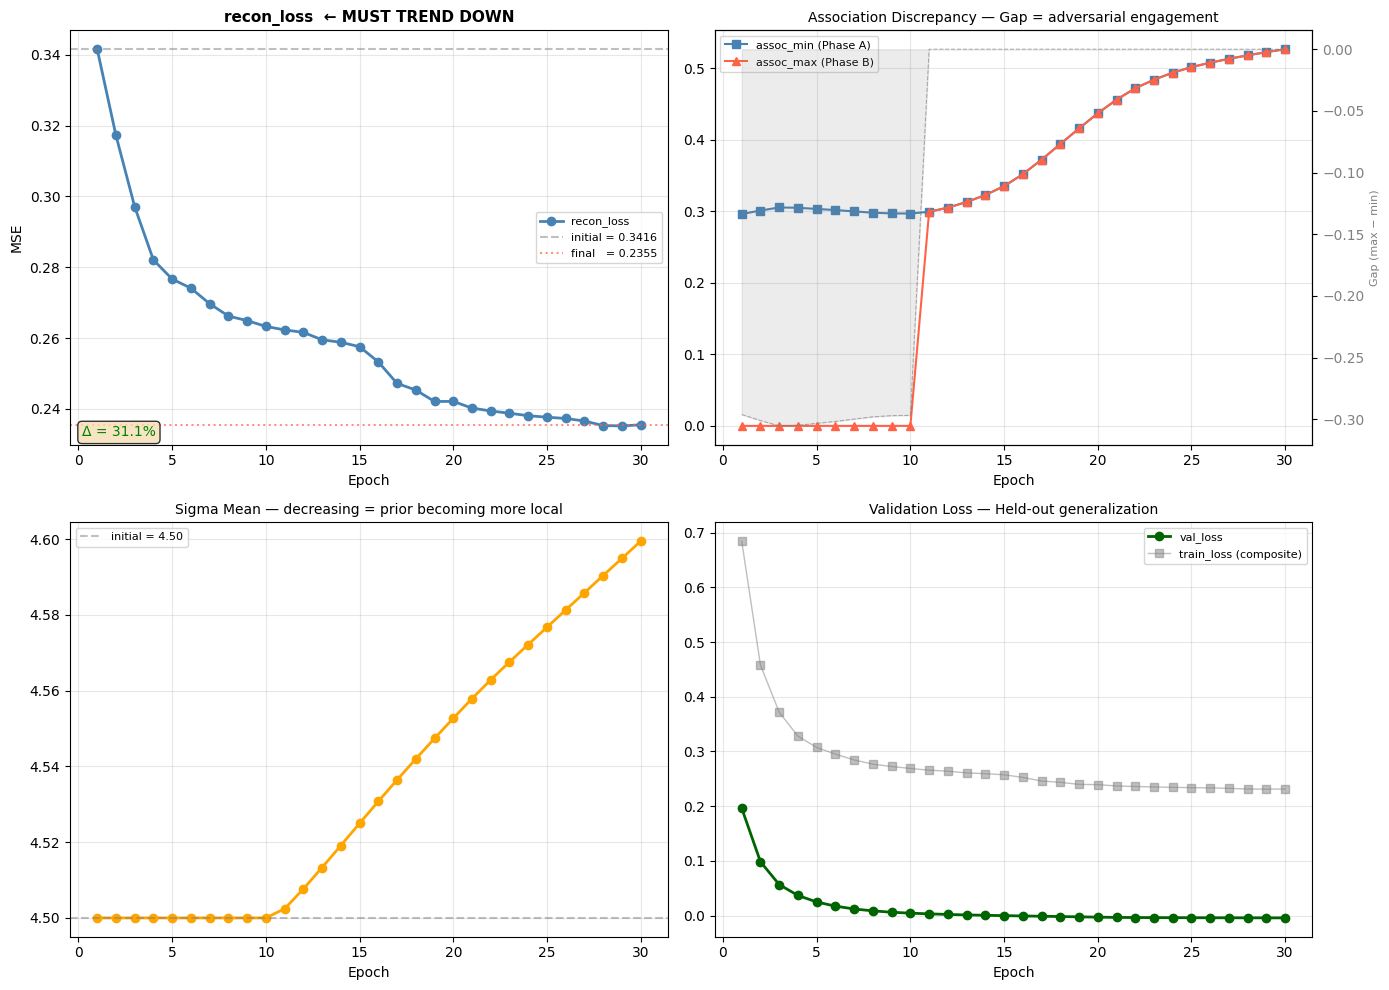

TRAINING HEALTH REPORT
  recon_loss:       0.3416 → 0.2355  (+31.1%)
  assoc gap:        -0.0000  (target: > 0 = adversarial game playing)
  sigma trend:      +0.0995  (target: < 0 = prior getting more local)
  val_loss:         0.1963 → -0.0043  (-0.2006)


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
epochs = range(1, len(history["loss"]) + 1)

# --- (0,0): recon_loss — primary health signal ---
ax = axes[0, 0]
ax.plot(epochs, history["recon_loss"], marker="o", color="steelblue", lw=2, label="recon_loss")
ax.axhline(y=history["recon_loss"][0], color="gray", ls="--", alpha=0.5,
           label=f"initial = {history['recon_loss'][0]:.4f}")
ax.axhline(y=history["recon_loss"][-1], color="tomato", ls=":", alpha=0.7,
           label=f"final   = {history['recon_loss'][-1]:.4f}")
ax.set_title("recon_loss  ← MUST TREND DOWN", fontsize=11, fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Annotate improvement percentage
improvement = (history["recon_loss"][0] - history["recon_loss"][-1]) / history["recon_loss"][0] * 100
ax.text(0.02, 0.02, f"Δ = {improvement:.1f}%", transform=ax.transAxes,
        fontsize=10, color="green" if improvement > 5 else "red",
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))

# --- (0,1): assoc_min vs assoc_max — adversarial gap ---
ax = axes[0, 1]
ax.plot(epochs, history["assoc_loss_min"], marker="s", color="steelblue", lw=1.5,
        label="assoc_min (Phase A)")
ax.plot(epochs, history["assoc_loss_max"], marker="^", color="tomato", lw=1.5,
        label="assoc_max (Phase B)")
if len(history["assoc_loss_min"]) == len(history["assoc_loss_max"]):
    gap = [mx - mn for mx, mn in zip(history["assoc_loss_max"], history["assoc_loss_min"])]
    ax_twin = ax.twinx()
    ax_twin.fill_between(epochs, gap, alpha=0.15, color="gray")
    ax_twin.plot(epochs, gap, color="gray", lw=0.8, ls="--", alpha=0.6)
    ax_twin.set_ylabel("Gap (max − min)", fontsize=8, color="gray")
    ax_twin.tick_params(axis="y", labelcolor="gray")
ax.set_title("Association Discrepancy — Gap = adversarial engagement", fontsize=10)
ax.set_xlabel("Epoch")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# --- (1,0): sigma_mean ---
ax = axes[1, 0]
ax.plot(epochs, history["sigma_mean"], marker="o", color="orange", lw=2)
ax.axhline(y=history["sigma_mean"][0], color="gray", ls="--", alpha=0.5,
           label=f"initial = {history['sigma_mean'][0]:.2f}")
ax.set_title("Sigma Mean — decreasing = prior becoming more local", fontsize=10)
ax.set_xlabel("Epoch")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# --- (1,1): val_loss (if available) ---
ax = axes[1, 1]
if "val_loss" in history and len(history["val_loss"]) > 0:
    ax.plot(epochs, history["val_loss"], marker="o", color="darkgreen", lw=2,
            label="val_loss")
    ax.plot(epochs, history["loss"], marker="s", color="gray", lw=1, alpha=0.5,
            label="train_loss (composite)")
    ax.set_title("Validation Loss — Held-out generalization", fontsize=10)
    ax.legend(fontsize=8)
else:
    ax.plot(epochs, history["loss"], marker="s", color="gray", lw=1.5,
            label="train_loss (composite, not a health signal)")
    ax.set_title("Total Loss = recon − λ·assoc + orth\n(composite — use recon_loss instead)", fontsize=10, color="gray")
    ax.legend(fontsize=8)
ax.set_xlabel("Epoch")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Print summary health report ---
print("=" * 55)
print("TRAINING HEALTH REPORT")
print("=" * 55)
print(f"  recon_loss:       {history['recon_loss'][0]:.4f} → {history['recon_loss'][-1]:.4f}  ({improvement:+.1f}%)")
assoc_gap = history['assoc_loss_max'][-1] - history['assoc_loss_min'][-1]
print(f"  assoc gap:        {assoc_gap:.4f}  (target: > 0 = adversarial game playing)")
sigma_delta = history['sigma_mean'][-1] - history['sigma_mean'][0]
print(f"  sigma trend:      {sigma_delta:+.4f}  (target: < 0 = prior getting more local)")
if "val_loss" in history and len(history["val_loss"]) > 0:
    val_trend = history["val_loss"][-1] - history["val_loss"][0]
    print(f"  val_loss:         {history['val_loss'][0]:.4f} → {history['val_loss'][-1]:.4f}  ({val_trend:+.4f})")
print("=" * 55)

## 7. Model Evaluation — AUROC / AUPRC

Reconstruction loss alone doesn't tell us if the model separates normal from anomalous.
We evaluate using `MaskFormerEvaluator` with synthetic anomalies (normal windows + injected noise/spikes).

> **AUROC** = Area Under ROC Curve — probability that a random anomaly scores higher than a random normal.
> **AUPRC** = Area Under Precision-Recall Curve — more informative when anomalies are rare.
>
> Both range 0–1: 0.5 = random, 1.0 = perfect separation.

In [11]:
from app.anomaly_detection.training.maskformer_trainer import MaskFormerEvaluator
from app.anomaly_detection.layers.scorer import MADThreshold

device_str_eval = "cuda" if torch.cuda.is_available() else "cpu"

# --- Prepare normal files ---
normal_files = [
    {"input": torch.tensor(w, dtype=torch.float32).unsqueeze(0).to(device_str_eval),
     "robot_idx": torch.tensor([r], dtype=torch.long).to(device_str_eval),
     "program_idx": torch.tensor([p], dtype=torch.long).to(device_str_eval)}
    for w, r, p in zip(windows_arr[val_idx][:100], robot_arr[val_idx][:100], program_arr[val_idx][:100])
]

# --- Compute per-sensor global std from training windows ---
# This gives us the absolute scale of each sensor:
#   wire_feed_speed_mm_min  ~100s mm/min
#   wire_temperature_c      ~10s °C
#   welding_current_a       ~10s A
sensor_stds = windows_arr[train_idx].std(axis=(0, 2))  # [C]
print(f"Per-sensor global std: {sensor_stds}")
print(f"  (anomaly injection will use 6-10x these values)")

# --- Create synthetic anomalies — 3 types, all survive PerPatchRevIN ---
# PerPatchRevIN normalizes each patch to zero-mean/unit-std, which erases pure
# amplitude/offset shifts. Anomaly types that survive normalization:
#
#   spike:     A large-amplitude impulse in a sub-patch region creates a shape
#              distortion that remains after local normalization.
#   highfreq:  Sinusoidal oscillation with a frequency absent from normal data
#              changes the normalized shape of the patch.
#   flatline:  Replacing a region with near-constant values creates an unusually
#              smooth patch after normalization.
anomaly_files = []
np.random.seed(42)
PATCH_SIZE = model.patch_size  # 32

for w, r, p in zip(windows_arr[val_idx][:100], robot_arr[val_idx][:100], program_arr[val_idx][:100]):
    w_anom = w.copy()
    anom_len = PATCH_SIZE * 2           # affect 2 patch widths
    anom_start = np.random.randint(0, max(1, w.shape[1] - anom_len))
    anom_type = np.random.randint(3)

    if anom_type == 0:
        # Spike: 8σ impulse over a quarter-patch (sub-patch → distorts local shape)
        spike_half = PATCH_SIZE // 4
        center = anom_start + anom_len // 2
        for c in range(w.shape[0]):
            direction = np.random.choice([-1, 1])
            w_anom[c, center - spike_half:center + spike_half] += (
                8.0 * sensor_stds[c] * direction
            )

    elif anom_type == 1:
        # High-frequency oscillation: 8 cycles per anomaly window
        t = np.arange(anom_len)
        freq = 8.0 / anom_len
        for c in range(w.shape[0]):
            w_anom[c, anom_start:anom_start + anom_len] += (
                4.0 * sensor_stds[c] * np.sin(2 * np.pi * freq * t)
            )

    else:
        # Flatline: clamp to local mean ± small noise → patch shape becomes flat
        for c in range(w.shape[0]):
            seg_mean = w_anom[c, anom_start:anom_start + anom_len].mean()
            w_anom[c, anom_start:anom_start + anom_len] = (
                seg_mean + np.random.normal(0, 0.02 * sensor_stds[c], anom_len)
            )

    anomaly_files.append({
        "input": torch.tensor(w_anom, dtype=torch.float32).unsqueeze(0).to(device_str_eval),
        "robot_idx": torch.tensor([r], dtype=torch.long).to(device_str_eval),
        "program_idx": torch.tensor([p], dtype=torch.long).to(device_str_eval),
    })

# Sanity check: anomaly must differ visibly from its original
sample_w = windows_arr[val_idx][0]
sample_anom = anomaly_files[0]["input"].squeeze(0).cpu().numpy()
max_diff = np.abs(sample_anom - sample_w).max(axis=1)
print(f"\nSanity check — max diff per sensor (should be > 10): {max_diff}")

print(f"\nNormal files:   {len(normal_files)}")
print(f"Anomaly files:  {len(anomaly_files)}")

# --- Evaluate (uses compute_anomaly_score: absolute raw recon mean, no per-sample norm) ---
evaluator = MaskFormerEvaluator(model)
result = evaluator.evaluate(normal_files, anomaly_files)

print(f"\n{'='*45}")
print(f"AUROC:  {result.auroc:.4f}")
print(f"AUPRC:  {result.auprc:.4f}")
print(f"Threshold (MAD): {result.threshold:.6f}")
print(f"Samples: {result.num_normal} normal, {result.num_anomaly} anomaly")
print(f"{'='*45}")
if result.auroc > 0.7:
    print("Good separation — anomaly signal present.")
elif result.auroc > 0.5:
    print("Weak separation — model detects some anomalies. Try more training epochs.")
else:
    print("Near-random — check anomaly injection and model training.")


Per-sensor global std: [ 0.8070678 70.16212   42.582203 ]
  (anomaly injection will use 6-10x these values)

Sanity check — max diff per sensor (should be > 10): [  6.4565425 561.29694   340.65765  ]

Normal files:   100
Anomaly files:  100

AUROC:  0.9422
AUPRC:  0.9529
Threshold (MAD): 0.272570
Samples: 100 normal, 100 anomaly
Good separation — anomaly signal present.


3-WAY AUROC DECOMPOSITION
  recon_raw:  0.9110  (shape distortion in normalized patches)
  assoc_raw:  0.6983  (attention concentration anomaly)
  combined:   0.8972  (global-norm product — for localization)

Score ranges (normal | anomaly):
  recon: [0.1818, 0.3073] | [0.1861, 0.5654]
  assoc: [-0.5635, -0.5419] | [-0.5642, -0.5322]


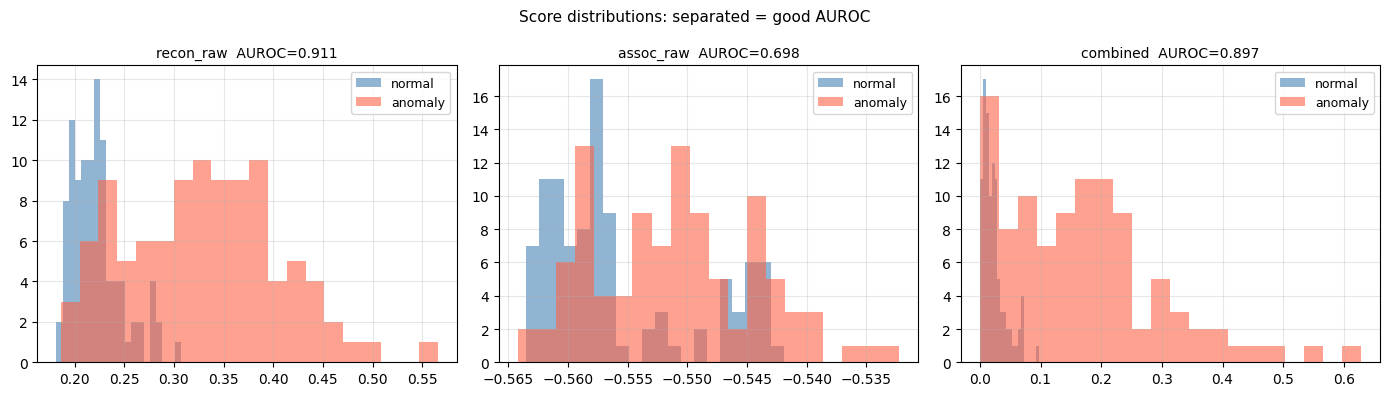

In [12]:
## 7b. AUROC Decomposition — recon_raw vs assoc_raw vs combined
#
# compute_anomaly_score returns absolute mean recon error (no per-sample normalization).
# Here we also expose the raw assoc signal so we can see which one actually separates.
#
# PerPatchRevIN note (proposal 5):
#   recon_raw measures shape distortions within each patch after RevIN normalization.
#   Amplitude/offset faults that are uniform across a full patch are ERASED by RevIN
#   and will NOT appear in recon_raw. Use signal-specific spike/flatline/highfreq
#   anomaly types (see cell 18) to create shape distortions that survive normalization.

model.eval()
_device = next(model.parameters()).device

def compute_decomposed_scores(files):
    recon_list, assoc_list = [], []
    for batch in files:
        bd = {k: v.to(_device) if isinstance(v, torch.Tensor) else v for k, v in batch.items()}
        recon_score, assoc_score = model._compute_token_scores(bd, fast=True)
        recon_list.append(recon_score.mean(dim=-1).item())     # absolute mean MSE
        assoc_list.append(assoc_score.mean(dim=-1).item())     # mean negative discrepancy
    return recon_list, assoc_list

normal_recon, normal_assoc = compute_decomposed_scores(normal_files)
anomaly_recon, anomaly_assoc = compute_decomposed_scores(anomaly_files)

def auroc_1d(normal_scores, anomaly_scores):
    """Mann-Whitney AUROC: P(anomaly_score > normal_score)."""
    concordant = sum(
        sum(1.0 for ns in normal_scores if a_s > ns) +
        0.5 * sum(1.0 for ns in normal_scores if a_s == ns)
        for a_s in anomaly_scores
    )
    return concordant / (len(normal_scores) * len(anomaly_scores))

auroc_recon = auroc_1d(normal_recon, anomaly_recon)
auroc_assoc = auroc_1d(normal_assoc, anomaly_assoc)

# Combined: multiply globally-normalized scores (batch-level norm, not per-sample)
all_r = normal_recon + anomaly_recon
all_a = normal_assoc + anomaly_assoc
r_min, r_max = min(all_r), max(all_r)
a_min, a_max = min(all_a), max(all_a)
def gnorm(x, mn, mx): return (x - mn) / (mx - mn + 1e-8)
normal_comb   = [gnorm(r, r_min, r_max) * gnorm(a, a_min, a_max) for r, a in zip(normal_recon, normal_assoc)]
anomaly_comb  = [gnorm(r, r_min, r_max) * gnorm(a, a_min, a_max) for r, a in zip(anomaly_recon, anomaly_assoc)]
auroc_combined = auroc_1d(normal_comb, anomaly_comb)

print("=" * 50)
print("3-WAY AUROC DECOMPOSITION")
print("=" * 50)
print(f"  recon_raw:  {auroc_recon:.4f}  (shape distortion in normalized patches)")
print(f"  assoc_raw:  {auroc_assoc:.4f}  (attention concentration anomaly)")
print(f"  combined:   {auroc_combined:.4f}  (global-norm product — for localization)")
print("=" * 50)
print(f"\nScore ranges (normal | anomaly):")
print(f"  recon: [{min(normal_recon):.4f}, {max(normal_recon):.4f}] | [{min(anomaly_recon):.4f}, {max(anomaly_recon):.4f}]")
print(f"  assoc: [{min(normal_assoc):.4f}, {max(normal_assoc):.4f}] | [{min(anomaly_assoc):.4f}, {max(anomaly_assoc):.4f}]")

# Visualize score distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (ns, as_, lbl) in zip(axes, [
    (normal_recon, anomaly_recon, f"recon_raw  AUROC={auroc_recon:.3f}"),
    (normal_assoc, anomaly_assoc, f"assoc_raw  AUROC={auroc_assoc:.3f}"),
    (normal_comb, anomaly_comb, f"combined  AUROC={auroc_combined:.3f}"),
]):
    ax.hist(ns, bins=20, alpha=0.6, label="normal",  color="steelblue")
    ax.hist(as_, bins=20, alpha=0.6, label="anomaly", color="tomato")
    ax.set_title(lbl, fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
plt.suptitle("Score distributions: separated = good AUROC", fontsize=11)
plt.tight_layout()
plt.show()


## 8. Save Model Checkpoint

In [13]:
# Save model checkpoint using BaseAnomalyDetectionModel.save_manual_checkpoint
ckpt_dir = project_root / "artifacts" / "maskformer_checkpoint_real"
model.save_manual_checkpoint(
    epoch=EPOCHS,
    val_loss=history["loss"][-1],
    folder_path=str(ckpt_dir),
    is_best=True,
)
print(f"Model state_dict saved to {ckpt_dir / f'model_{model.name}_best.pt'}")
print(f"Model metadata saved to {ckpt_dir / f'metadata_{model.name}_best.json'}")

# Also save training history and codebooks separately
extra = {
    "history": history,
    "robot_codebook": robot_to_idx,
    "program_codebook": program_to_idx,
}
with open(ckpt_dir / "training_extra.json", "w") as f:
    json.dump(extra, f, indent=2, default=str)
print(f"Training extras (history, codebooks) saved to {ckpt_dir / 'training_extra.json'}")
print("Done! ðŸŽ‰")


Model state_dict saved to /home/trietlm/TED-Hackathon-Agent/artifacts/maskformer_checkpoint_real/model_GLCAnomalyMaskFormer_best.pt
Model metadata saved to /home/trietlm/TED-Hackathon-Agent/artifacts/maskformer_checkpoint_real/metadata_GLCAnomalyMaskFormer_best.json
Training extras (history, codebooks) saved to /home/trietlm/TED-Hackathon-Agent/artifacts/maskformer_checkpoint_real/training_extra.json
Done! ðŸŽ‰


## 9. Diagnosis: Load Checkpoint & Visualize Reconstruction

Check whether the model learned to reconstruct masked patches, or collapsed to predicting near-zero.

In [16]:
import json, torch
from pathlib import Path
from app.anomaly_detection.models.glc_anomaly_maskformer import GLCAnomalyMaskFormer

ckpt_dir = project_root / "artifacts" / "maskformer_checkpoint_real"
device_str = "cuda" if torch.cuda.is_available() else "cpu"

model_ckpt = GLCAnomalyMaskFormer.load_from_checkpoint(
    checkpoint=str(ckpt_dir),
    model_file="model_GLCAnomalyMaskFormer_best.pt",
    metadata_file="metadata_GLCAnomalyMaskFormer_best.json",
    device=device_str,
)

with open(ckpt_dir / "training_extra.json") as f:
    extra_data = json.load(f)
history = extra_data["history"]

print(f"Loaded: {model_ckpt.name}")
print(f"  sensors={model_ckpt.num_sensors}  patches={model_ckpt.num_patches}"
      f"  patch_size={model_ckpt.patch_size}  stride={model_ckpt.patch_stride}")
sigma_vals = [layer.sigma.detach().cpu().mean().item()
              for layer in model_ckpt.transformer.layers]
print(f"  sigma/layer (mean over heads): {[f"{s:.2f}" for s in sigma_vals]}")

Loaded: GLCAnomalyMaskFormer
  sensors=3  patches=14  patch_size=32  stride=16
  sigma/layer (mean over heads): ['4.60', '4.60', '4.60', '4.60']


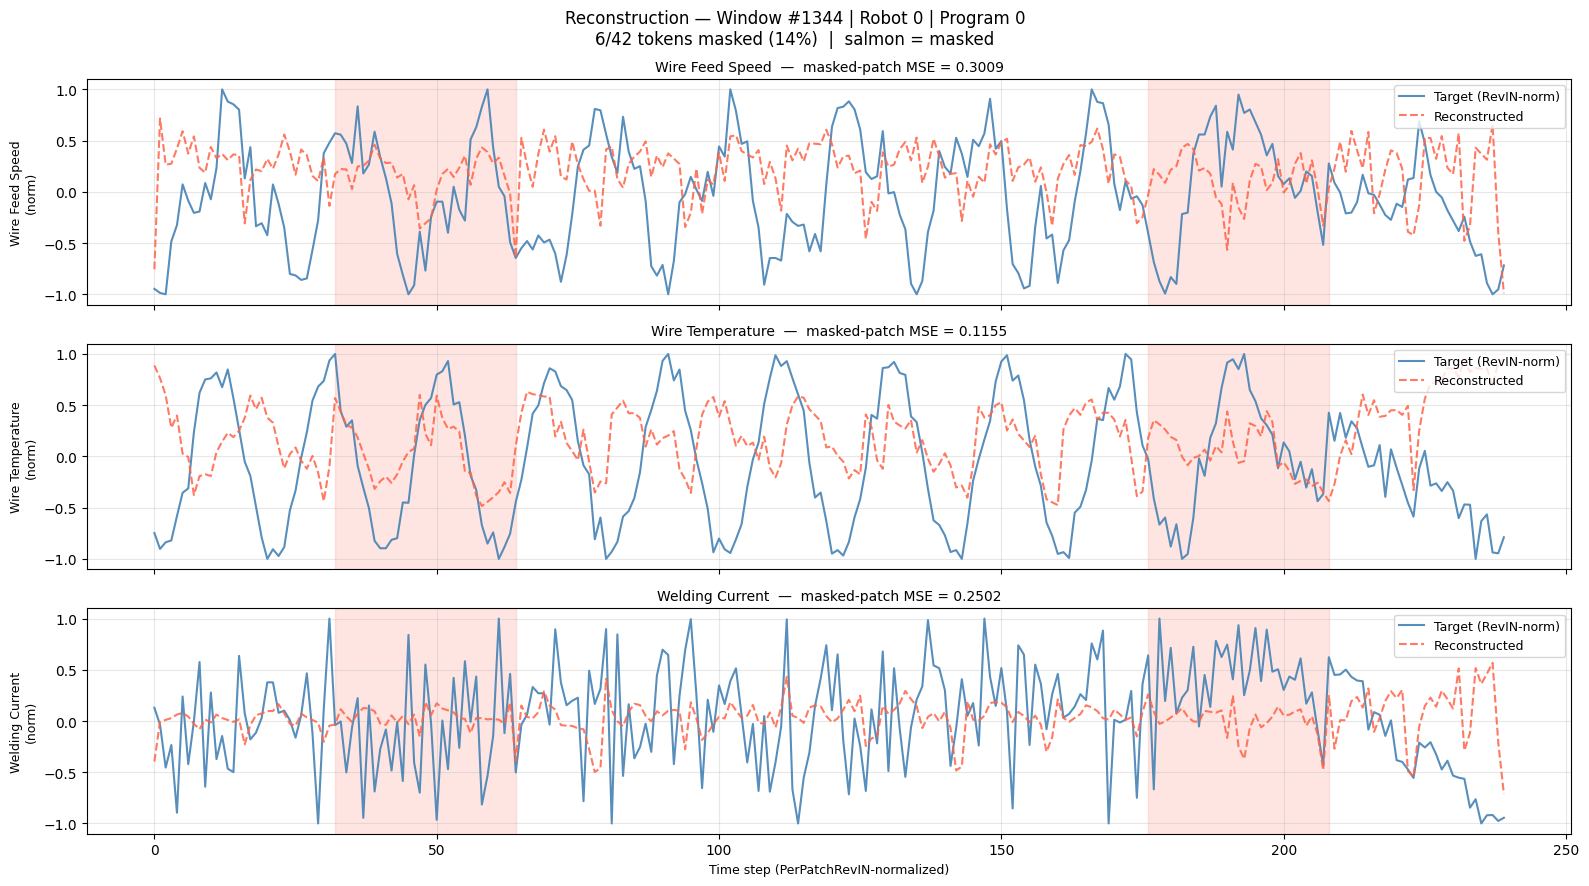


Masked-token target variance:  0.3199
Masked-token predict variance: 0.1056
Variance ratio (pred/target):  0.330  <- near 0 = collapsed, near 1 = good
Overall masked MSE:            0.2222
Training final recon_loss:     0.2355


In [17]:
import numpy as np
import matplotlib.pyplot as plt

WINDOW_IDX = 1344   # change to inspect different windows
SENSOR_NAMES = ["Wire Feed Speed", "Wire Temperature", "Welding Current"]

C  = model_ckpt.num_sensors   # 3
P  = model_ckpt.num_patches   # 14
PS = model_ckpt.patch_size    # 32
ST = model_ckpt.patch_stride  # 16

window_np  = windows_arr[WINDOW_IDX]
robot_i    = int(robot_arr[WINDOW_IDX])
program_i  = int(program_arr[WINDOW_IDX])

x_t       = torch.tensor(window_np, dtype=torch.float32).unsqueeze(0).to(device_str)
robot_t   = torch.tensor([robot_i],   dtype=torch.long).to(device_str)
program_t = torch.tensor([program_i], dtype=torch.long).to(device_str)

# Forward in TRAIN mode so masking is applied; fixed seed for reproducibility
torch.manual_seed(0)
model_ckpt.train()
with torch.no_grad():
    out = model_ckpt._forward_impl(
        x_t, robot_idx=robot_t, program_idx=program_t, detach_mode="none"
    )
model_ckpt.eval()

pred_np   = out["patches_pred"][0].cpu().numpy()    # [N, PS]
target_np = out["patches_target"][0].cpu().numpy()  # [N, PS] RevIN-normalized
mask_np   = out["mask"][0].cpu().numpy()            # [N] bool

pred_3d   = pred_np.reshape(C, P, PS)
target_3d = target_np.reshape(C, P, PS)
mask_2d   = mask_np.reshape(C, P)  # sensor-block: same time columns across all sensors


def patches_to_signal(patches_cp, stride, patch_size):
    """Average overlapping patches back to full time series."""
    C_, P_, L = patches_cp.shape
    T_ = (P_ - 1) * stride + patch_size
    sig = np.zeros((C_, T_))
    cnt = np.zeros((C_, T_))
    for p in range(P_):
        s = p * stride
        sig[:, s:s + L] += patches_cp[:, p, :]
        cnt[:, s:s + L] += 1
    return sig / np.maximum(cnt, 1)


target_sig = patches_to_signal(target_3d, ST, PS)
pred_sig   = patches_to_signal(pred_3d,   ST, PS)
T_len = target_sig.shape[1]

fig, axes = plt.subplots(C, 1, figsize=(16, 9), sharex=True)
for c in range(C):
    ax = axes[c]
    t  = np.arange(T_len)
    ax.plot(t, target_sig[c], color="steelblue", lw=1.5, label="Target (RevIN-norm)", alpha=0.9)
    ax.plot(t, pred_sig[c],   color="tomato",    lw=1.5, ls="--", label="Reconstructed", alpha=0.85)
    for p in np.where(mask_2d[0])[0]:  # sensor-block: same columns for all sensors
        ax.axvspan(p * ST, min(p * ST + PS, T_len), color="salmon", alpha=0.20)
    mse_per_patch = ((pred_3d[c] - target_3d[c]) ** 2).mean(axis=-1)
    masked_mse    = mse_per_patch[mask_2d[c]].mean() if mask_2d[c].any() else float("nan")
    ax.set_ylabel(f"{SENSOR_NAMES[c]}\n(norm)", fontsize=9)
    ax.set_title(f"{SENSOR_NAMES[c]}  —  masked-patch MSE = {masked_mse:.4f}", fontsize=10)
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time step (PerPatchRevIN-normalized)", fontsize=9)
n_masked = int(mask_np.sum())
fig.suptitle(
    f"Reconstruction — Window #{WINDOW_IDX} | Robot {robot_i} | Program {program_i}\n"
    f"{n_masked}/{C * P} tokens masked ({100 * n_masked / (C * P):.0f}%)  |  salmon = masked",
    fontsize=12,
)
plt.tight_layout()
plt.show()

# ---- Collapse diagnosis ----
pred_var = pred_3d[:, mask_2d[0], :].var()
tgt_var  = target_3d[:, mask_2d[0], :].var()
print(f"\nMasked-token target variance:  {tgt_var:.4f}")
print(f"Masked-token predict variance: {pred_var:.4f}")
print(f"Variance ratio (pred/target):  {pred_var / tgt_var:.3f}  <- near 0 = collapsed, near 1 = good")
overall_mse = float(((pred_3d - target_3d) ** 2 * mask_2d[..., None]).sum()) / (n_masked * PS)
print(f"Overall masked MSE:            {overall_mse:.4f}")
print(f"Training final recon_loss:     {history["recon_loss"][-1]:.4f}")